# EOD electric-field solver — *Gnathonemus petersii*, two-layer bodies, recorded waveform

Cleaned-up version of `eod_two_layer_pipeline.ipynb`: same physics, dead code and duplicated
solve logic removed, a couple of latent bugs fixed (see notes inline), one shared
`solve_source_fish` function instead of the same ~15 lines copy-pasted into every plotting cell.

**Setup.** Each fish is a two-layer body (conductive interior + resistive/capacitive skin,
literature values) sitting in water. One fish emits its *recorded* EOD waveform `I(t)`; the
other fish are passive boundaries that distort the field around it.

**Governing equation** (frequency domain, one angular frequency ω at a time):
$$\nabla\cdot(\gamma\,\nabla\hat\varphi) = -\hat s, \qquad \gamma = \sigma + i\omega\varepsilon$$
Solved once per EOD frequency that carries real power, then inverse-FFT'd to `φ(x, y, t)`.
The **E-field is not solved for directly** — it's recovered as `E = -∇φ` via a centered finite
difference (`np.gradient`) on the solved potential grid, same as in `efield_solver.py`.

# Shiv's mask fish identity: A = largest ... D = smallest
# Kaden's mask fish identity: index 0 = B, index 1 = A, index 2 = D, index 3 = C

# TO CHECK!!!!

In [1]:
import re
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.linalg import splu
from scipy.ndimage import zoom
from scipy.interpolate import UnivariateSpline
import matplotlib.pyplot as plt
from midline_methods import *
from compute_electric_field import *
import json

## 0. Load fish masks

`..._masks_first_1000_frames.npy` → `(n_fish, n_saved_frames, P, P)` boolean. We pick one saved
frame → `(n_fish, P, P)`. `N` is the tank's solve-grid resolution; `n_poles` is how many point
currents approximate one fish's body (a 1-D "multipole" chain along its midline).

In [2]:
mgz_file = 'data/video2024-02-20T21_16_26__223e__59997__masks_packed.mgz'
frame_idx = 2                                      # one of the 3 saved example frames (0, 600, 800)
fish_mask = np.load(f'{mgz_file}_masks_first_1000_frames.npy')[:, frame_idx]   # (n_fish, P, P) bool
n_fish = fish_mask.shape[0]
print(f"fish_mask: {fish_mask.shape} {fish_mask.dtype}, {n_fish} fish")

N = 200         # tank grid resolution (N x N)
n_poles = 100   # current sources placed along each fish's body (n_poles+1 points, tail->head)
h = 1.0 / (N - 1)

fish_mask: (4, 912, 912) bool, 4 fish


## 1. Geometry: grid bookkeeping, curved midline, multipole source placement

In [5]:
L_fish = {k: v['L_tank'] for k, v in json.load(open('results/fish_lengths_fixed.json'))['fish'].items()}
letter_of = {0: 'A', 1: 'B', 2: 'C', 3: 'D'}       # mask index -> fish letter in Shiv's

I_peak = 1 # to check whether it has to be smth else
sources = {}
for i in range(n_fish):
    if fish_mask[i].sum() < 50: continue                                  # fish not visible in this frame
    body = fish_midline_with_head(fish_mask[i], n_ctrl=n_poles + 1)       # one fish's mask at a time
    midline = body['midline']                                             # tail -> head by the area rule
    sources[i] = multipole_sources(midline, I0=I_peak, exp_length_scale=1, L=L_fish[letter_of[i]])

NameError: name 'multipole_sources' is not defined

# IN WHAT SENSE IS I0 A REAL RECORDED VOLTAGE AND THERE IS A DOUBLE COUNTING ???!!!

## 2. Two-layer material model

Normalized conductivities (`sigma_water = 1`), from Migliaro/Caputi/Budelli (2005):

| region | σ (conductivity) | ε (permittivity) | basis |
|---|---|---|---|
| water | 1.0 | 0 | resistive |
| interior | 200 | 0 | body ≈ 200× water (measured), funnels current |
| skin | 0.05 | 2.7e-6 | resistive sheet + capacitance → distorts the EOD waveform |

Capacitance lives only in the **skin**; that's what makes the field shape change across the EOD
rather than just scale with it.

In [3]:
MAT = dict(
    sigma_water=1.0,      eps_water=0.0,
    sigma_interior=200.0, eps_interior=0.0,
    sigma_skin=0.05,      eps_skin=2.7e-6,
)

def gammas(omega, **mat):
    """Complex admittivity gamma = sigma + i*omega*eps, per material."""
    gw = mat['sigma_water']    + 1j*omega*mat['eps_water']
    gs = mat['sigma_skin']     + 1j*omega*mat['eps_skin']
    gi = mat['sigma_interior'] + 1j*omega*mat['eps_interior']
    return gw, gs, gi

## 3. Body geometry on the grid + matrix assembly

`occupancy_field` is a smoothly-interpolated occupancy level-set (not a binary mask), so the
water|fish boundary can sit *between* grid points. `build_A_shell` places the skin as a
sub-cell shell offset inward from that boundary by `delta_h` cells, and composes
water→skin→interior in series per edge — so the resistive+capacitive skin is resolved without
needing a finer grid. `A` is complex-symmetric, so it's solved with a direct LU, not CG.

In [5]:
def occupancy_field(masks, N, skip=None):
    """(n_fish,P,P) bool -> smooth NxN occupancy in [0,1]; occ > 0.5 = inside a fish.
       Linear interpolation keeps fractional values at the boundary. `skip` excludes one fish
       (the emitter) so it's transparent to water."""
    occ = np.zeros((N, N))
    for f, m in enumerate(masks):
        if f == skip or not np.any(m): continue
        P = m.shape[0]
        occ = np.maximum(occ, zoom(m.astype(float), N / P, order=1)[:N, :N])
    return occ

def theta_outer(occ, level=0.5):
    """Fractional position of the water|fish boundary on each grid edge (NaN = uncut)."""
    def cross(a, b):
        cut = (a - level) * (b - level) < 0
        d = a - b
        th = np.divide(a - level, d, out=np.full_like(a, np.nan), where=np.abs(d) > 1e-12)
        return np.where(cut, np.clip(th, 1e-6, 1 - 1e-6), np.nan)
    return cross(occ[:-1, :], occ[1:, :]), cross(occ[:, :-1], occ[:, 1:])

def _edge_weight(gC, gM, occC, occM, thc, delta_h, g_water, g_skin, g_interior):
    """Effective admittivity across one grid edge, composing water|skin|interior in SERIES.
       thc = outer (water|fish) crossing from node C; delta_h = skin thickness in cell units."""
    if np.isnan(thc):
        return gC if gC == gM else 2*gC*gM/(gC+gM)         # uncut edge: harmonic mean
    inward = 1.0 if occM > occC else -1.0
    th_in = thc + inward * delta_h                          # inner (skin|interior) crossing
    cuts = sorted(t for t in (thc, th_in) if 1e-6 < t < 1 - 1e-6)
    pts = [0.0] + cuts + [1.0]
    Z = 0.0
    for a, b in zip(pts[:-1], pts[1:]):
        xm = 0.5 * (a + b)
        d_out, d_in = (xm - thc) * inward, (xm - th_in) * inward
        g = g_water if d_out < 0 else (g_interior if d_in > 0 else g_skin)
        Z += (b - a) / g
    return 1.0 / Z

def build_A_shell(occ, N, delta_h, g_water, g_skin, g_interior):
    """Complex system matrix for div(gamma grad phi) = -s, with the skin resolved as a
       sub-cell shell at the actual occupancy boundary (not snapped to the grid)."""
    tx, ty = theta_outer(occ)
    gnode = np.where(occ > 0.5, g_interior, g_water)
    r, c, v = [], [], []
    def edge(k, kk, gC, gM, oC, oM, thc):
        w = _edge_weight(gC, gM, oC, oM, thc, delta_h, g_water, g_skin, g_interior)
        r.append(k); c.append(kk); v.append(w); return w
    for i in range(N):
        for j in range(N):
            k = idx(i, j, N); ws = 0j
            if i > 0:   ws += edge(k, idx(i-1,j,N), gnode[i,j], gnode[i-1,j], occ[i,j], occ[i-1,j], 1-tx[i-1,j])
            if i < N-1: ws += edge(k, idx(i+1,j,N), gnode[i,j], gnode[i+1,j], occ[i,j], occ[i+1,j],   tx[i,  j])
            if j > 0:   ws += edge(k, idx(i,j-1,N), gnode[i,j], gnode[i,j-1], occ[i,j], occ[i,j-1], 1-ty[i,j-1])
            if j < N-1: ws += edge(k, idx(i,j+1,N), gnode[i,j], gnode[i,j+1], occ[i,j], occ[i,j+1],   ty[i,  j])
            r.append(k); c.append(k); v.append(-ws)
    return sp.coo_matrix((v, (r, c)), shape=(N*N, N*N), dtype=complex).tocsr()

def solve_potential(A, b, pin=0):
    """Solve A phi = b (singular complex Neumann system); pin one node to fix the gauge."""
    M = (-A).tolil(); rhs = -np.asarray(b).ravel().astype(complex)
    M[pin, :] = 0; M[pin, pin] = 1; rhs[pin] = 0
    phi = splu(M.tocsc()).solve(rhs)
    return phi - phi.mean()

## 4. Source deposition on the grid

Each point current is spread onto its 4 surrounding grid nodes by bilinear weights.

In [6]:
def place_current_on_grid(b, x, y, I, h, N):
    fi, fj = x/h, y/h; i, j = int(fi), int(fj); a, c = fi-i, fj-j
    for di, wx in ((0, 1-a), (1, a)):
        for dj, wy in ((0, 1-c), (1, c)):
            ii, jj = i+di, j+dj
            if 0 <= ii < N and 0 <= jj < N: b[ii, jj] += I*wx*wy

def build_multipole_b(pos, cur, h, N):
    b = np.zeros((N, N))
    for (x, y), Ii in zip(pos, cur): place_current_on_grid(b, x, y, Ii, h, N)
    return b - b.mean()            # enforce net current = 0 (required for the Neumann solve)

## 5. Recorded EOD → I(t), its power spectrum, and the electrode layout

Only the rfft bins that carry `power_keep` of the signal's power are solved for (the rest are
noise and would just waste LU factorizations).

In [7]:
def load_eod_row(df, row=0, fs=20000.0):
    """One EOD row of the CSV -> E (n_elec, n_time), index of the most active electrode, dt."""
    pat = re.compile(r"electrode_(\d+)_time_(\d+)")
    cells = [(int(m.group(1)), int(m.group(2)), col) for col in df.columns for m in [pat.match(col)] if m]
    ne, nt = max(e for e, _, _ in cells), max(t for _, t, _ in cells)
    E = np.full((ne, nt), np.nan)
    for e, t, col in cells: E[e-1, t-1] = df.iloc[row][col]
    best = int(np.argmax(E.std(axis=1)))                   # most active electrode
    return E, best, 1.0/fs

def eod_frequencies(I_rec, dt, power_keep=0.999, detrend=True):
    """Which rfft bins carry `power_keep` of the signal's power (amplitude is irrelevant)."""
    x = np.asarray(I_rec, float); x = x - x.mean() if detrend else x
    n = len(x); Ihat = np.fft.rfft(x); f = np.fft.rfftfreq(n, dt); Pw = np.abs(Ihat)**2
    order = np.argsort(Pw)[::-1]; frac = np.cumsum(Pw[order]) / Pw.sum()
    nk = int(np.searchsorted(frac, power_keep) + 1)
    keep = np.sort(order[:nk]); keep = keep[f[keep] > 0]    # drop DC
    return keep, 2*np.pi*f, Ihat, n, f, Pw

def load_electrode_pairs(csv, N_px=912):
    """Electrode (x,y) pixel coords -> [0,1] tank-frame coords, grouped into +/- pairs."""
    df = pd.read_csv(csv)
    pairs = []
    for _, r in df.iterrows():
        if str(r['pol1']).strip() == '+':
            (x1, y1), (x2, y2) = (r['x1'], r['y1']), (r['x2'], r['y2'])
        else:
            (x1, y1), (x2, y2) = (r['x2'], r['y2']), (r['x1'], r['y1'])
        to_tank = lambda x, y: np.array([y/(N_px-1), x/(N_px-1)])   # matches the mask/tank axes
        pairs.append((int(r['pair']), to_tank(x1, y1), to_tank(x2, y2)))
    return pairs

electrode #1 | 25 samples @ 20 kHz | solving 9 freqs: [0.8 1.6 2.4 3.2 4.  4.8 5.6 6.4 7.2] kHz


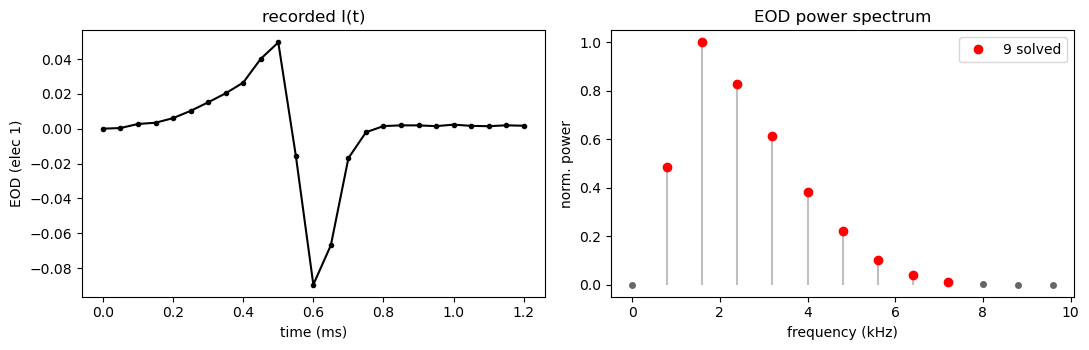

In [8]:
eod_csv = 'data/Data_4fish_2024-02-20T21_16_26.csv'
df_eod = pd.read_csv(eod_csv)

chosen_eod_frame = 25
E, best, dt = load_eod_row(df_eod, row=chosen_eod_frame, fs=20000.0)
I_rec = E[best]
It = I_rec - I_rec.mean()
keep, om, Ihat, n_t, freqs, Pw = eod_frequencies(I_rec, dt)
print(f"electrode #{best+1} | {n_t} samples @ {1/dt/1e3:.0f} kHz | "
      f"solving {len(keep)} freqs: {np.round(freqs[keep]/1e3, 2)} kHz")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(np.arange(n_t)*dt*1e3, It, 'ko-', ms=3)
ax[0].set_xlabel("time (ms)"); ax[0].set_ylabel(f"EOD (elec {best+1})"); ax[0].set_title("recorded I(t)")
ax[1].vlines(freqs/1e3, 0, Pw/Pw.max(), color='0.75')
ax[1].plot(freqs/1e3, Pw/Pw.max(), 'o', color='0.4', ms=4)
ax[1].plot(freqs[keep]/1e3, (Pw/Pw.max())[keep], 'ro', label=f"{len(keep)} solved")
ax[1].set_xlabel("frequency (kHz)"); ax[1].set_ylabel("norm. power"); ax[1].set_title("EOD power spectrum")
ax[1].legend(); plt.tight_layout(); plt.show()

electrode_locations_file = 'data/electrodes_signed_px_coord_2024-02-13.csv'
pairs = load_electrode_pairs(electrode_locations_file)

## 6. Core solver: one fish emits, the others are two-layer boundaries

One function, called for every (source fish × time-domain field) below — the original notebook
rebuilt this same ~15-line block inline in five separate plotting cells (and in one of them read
a stale `occ_with` left over from a previous cell instead of that cell's own `occ`; harmless only
because the two conductivities happened to cancel out algebraically there). Solving per-frequency
is always needed here since the skin is capacitive (`eps_skin != 0`), so there's no resistive
shortcut to fall back on.

In [9]:
def solve_source_fish(fish_mask, N, source_fish, Ihat, om, keep, n_t, delta_h=0.5,
                       n_poles=100, **mat):
    """Full-grid phi(x,y,t) for `source_fish` emitting (its own body is transparent to
       water). Solved once per kept EOD frequency, then inverse-FFT'd. Returns both:
       - phi_with:  the other fish present as two-layer (skin+interior) shell bodies
       - phi_water: identical source/geometry but uniform water everywhere (gw=gs=gi)
       so phi_with - phi_water isolates the perturbation caused by the OTHER fish."""
    h = 1.0 / (N - 1)
    midline = fish_midline_from_mask(fish_mask[source_fish])
    pos, cur = multipole_sources(midline, n=n_poles, I0=1.0)
    b_unit = build_multipole_b(pos, cur, h, N)
    occ = occupancy_field(fish_mask, N, skip=source_fish)

    psi_with  = np.zeros((len(om), N*N), complex)
    psi_water = np.zeros((len(om), N*N), complex)
    for k in keep:
        gw, gs, gi = gammas(om[k], **mat)
        psi_with[k]  = solve_potential(build_A_shell(occ, N, delta_h, gw, gs, gi), b_unit)
        psi_water[k] = solve_potential(build_A_shell(occ, N, delta_h, gw, gw, gw), b_unit)

    phi_with  = np.fft.irfft(Ihat[:, None] * psi_with,  n=n_t, axis=0)
    phi_water = np.fft.irfft(Ihat[:, None] * psi_water, n=n_t, axis=0)
    return dict(phi_with=phi_with, phi_water=phi_water, pos=pos, cur=cur)

## 7. Sanity check

The emitting fish must be excluded from its own body's geometry (it's a source, not an
obstacle) — otherwise the solve would double-count its skin as a boundary around its own
current sources.

In [10]:
source_fish = 0
occ_check = occupancy_field(fish_mask, N, skip=source_fish)
on_src_body = occ_check[mask_to_grid(fish_mask[source_fish], N)]
assert on_src_body.max() < 0.5, "source fish leaking into its own occupancy field"
print("OK: source fish is excluded from its own body geometry")

OK: source fish is excluded from its own body geometry


## 8. Example field frames, using the actual fish bodies

Source fish 0 (dashed yellow outline) emits; fish 1-3 (solid lime outlines) are real body masks
from the tracked video frame. Top row: potential `φ` with streamlines of `E = -∇φ` (finite
difference via `np.gradient`, not an analytic gradient). Bottom row: the perturbation
`Δφ = φ_with − φ_without` caused by the other fish — since the skin is capacitive, this changes
*shape*, not just amplitude, across the EOD.

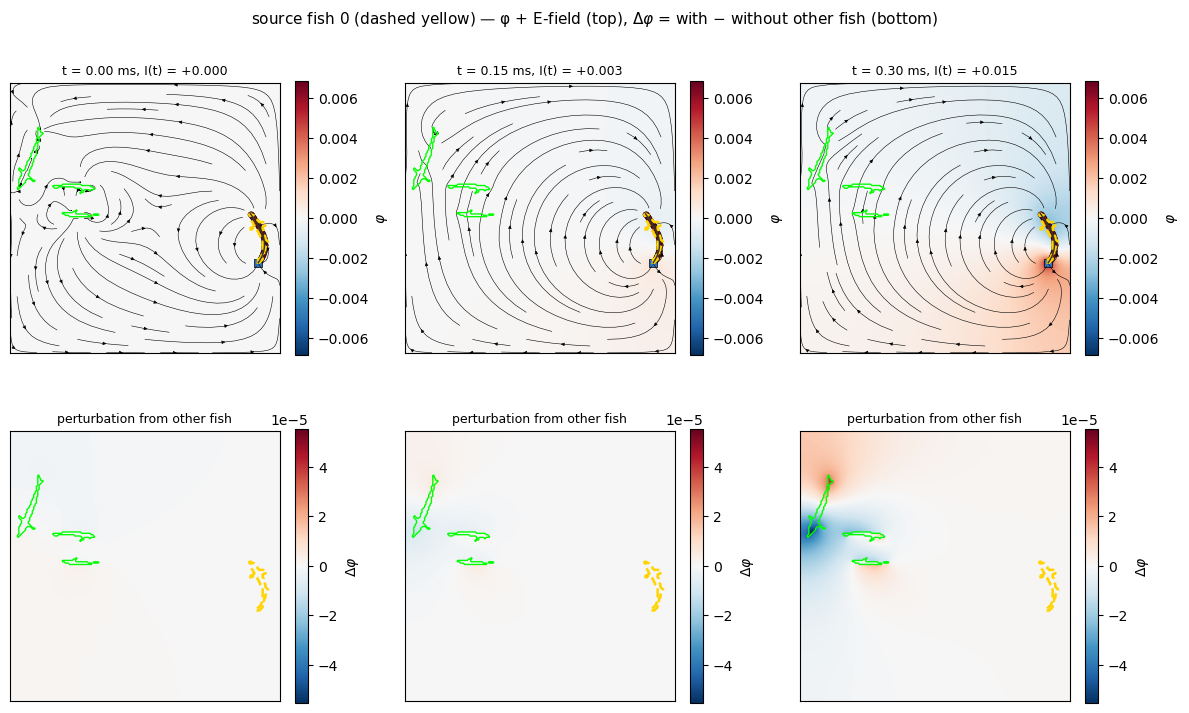

In [11]:
source_fish = 0
delta_h = 0.5                        # skin thickness, in grid-cell units
res = solve_source_fish(fish_mask, N, source_fish, Ihat, om, keep, n_t,
                         delta_h=delta_h, n_poles=n_poles, **MAT)
phi_with, phi_water, pos, cur = res['phi_with'], res['phi_water'], res['pos'], res['cur']
dphi = phi_with - phi_water
srcp, snkp = cur > 0, cur < 0

half = n_t // 2
vP = np.percentile(np.abs(phi_with[:half]), 99.5)
vD = np.percentile(np.abs(dphi[:half]), 99.0)
g = np.linspace(0, 1, N)

def outline(ax):
    for f, m in enumerate(fish_mask):
        if not m.any(): continue
        is_src = f == source_fish
        ax.contour(g, g, mask_to_grid(m, N).T.astype(float), levels=[0.5],
                   colors=["#FFD400" if is_src else "lime"],
                   linewidths=1.8 if is_src else 1.0, linestyles="--" if is_src else "-")

frames = [0, n_t // 8, n_t // 4]       # a few example timepoints across the first quarter of the EOD
fig, axes = plt.subplots(2, len(frames), figsize=(4*len(frames), 7.5))
for col, ti in enumerate(frames):
    phi, dp = to_grid(phi_with[ti], N), to_grid(dphi[ti], N)
    dpx, dpy = np.gradient(phi, h); Ex, Ey = -dpx, -dpy     # E = -grad(phi), finite-difference approx

    ax = axes[0, col]
    im = ax.imshow(phi.T, origin="lower", extent=[0,1,0,1], cmap="RdBu_r", vmin=-vP, vmax=vP)
    if np.ptp(phi) > 0: ax.streamplot(g, g, Ex.T, Ey.T, color="k", density=0.7, linewidth=0.4, arrowsize=0.5)
    outline(ax); ax.plot(pos[:,0], pos[:,1], "-", color="0.2", lw=1)
    ax.scatter(*pos[srcp].T, c="#C0392B", s=14, ec="k", lw=0.3)
    ax.scatter(*pos[snkp].T, marker="s", c="#2C6FBB", s=32, ec="k", lw=0.5)
    fig.colorbar(im, ax=ax, fraction=0.046, label=r"$\varphi$")
    ax.set_title(f"t = {ti*dt*1e3:.2f} ms, I(t) = {It[ti]:+.3f}", fontsize=9)

    ax = axes[1, col]
    im = ax.imshow(dp.T, origin="lower", extent=[0,1,0,1], cmap="RdBu_r", vmin=-vD, vmax=vD)
    outline(ax)
    fig.colorbar(im, ax=ax, fraction=0.046, label=r"$\Delta\varphi$")
    ax.set_title("perturbation from other fish", fontsize=9)

for ax in axes.ravel():
    ax.set_xlim(0,1); ax.set_ylim(0,1); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"source fish {source_fish} (dashed yellow) — φ + E-field (top), "
             r"$\Delta\varphi$ = with $-$ without other fish (bottom)", fontsize=11)
plt.tight_layout(); plt.show()

## 9. Compare simulated vs. recorded electrode-pair voltages

For each fish in turn as the assumed emitter, sample the solved field at the real electrode-pair
locations and compare to the recorded trace — this is the check for whether the model (and which
candidate source fish) reproduces the real measurement.

In [12]:
def sample_phi_t(phi_t, p, h, N):
    """Bilinear sample of a (n_t, N*N) field at tank-frame point p=(x,y)."""
    fi, fj = p[0]/h, p[1]/h; i, j = int(fi), int(fj); a, c = fi-i, fj-j
    w = lambda ii, jj: phi_t[:, idx(min(max(ii,0),N-1), min(max(jj,0),N-1), N)]
    return (1-a)*(1-c)*w(i,j) + a*(1-c)*w(i+1,j) + (1-a)*c*w(i,j+1) + a*c*w(i+1,j+1)

def rec_trace(pid, row):
    et = [f'electrode_{pid}_time_{i}' for i in range(1, n_t + 1)]
    vr = np.array(df_eod.loc[row, et], dtype=float)
    return vr - vr.mean()

V_rec = {pid: rec_trace(pid, chosen_eod_frame) for pid, _, _ in pairs}
rec_peak = max(np.abs(v).max() for v in V_rec.values())
V_rec = {pid: v / rec_peak for pid, v in V_rec.items()}          # recorded peak -> 1

V_sim = {}                                                       # V_sim[source_fish][pid]
for sf in range(n_fish):
    res = solve_source_fish(fish_mask, N, sf, Ihat, om, keep, n_t,
                             delta_h=delta_h, n_poles=n_poles, **MAT)
    V_pairs = {pid: sample_phi_t(res['phi_with'], pp, h, N) - sample_phi_t(res['phi_with'], pm, h, N)
               for pid, pp, pm in pairs}
    sim_peak = max(np.abs(v).max() for v in V_pairs.values())
    V_sim[sf] = {pid: v / sim_peak for pid, v in V_pairs.items()}  # each fish's own peak -> 1
    print(f"solved fish {sf} as source (peak |V| = {sim_peak:.3g})")

solved fish 0 as source (peak |V| = 0.0263)


solved fish 1 as source (peak |V| = 0.032)


solved fish 2 as source (peak |V| = 0.00402)


solved fish 3 as source (peak |V| = 0.00632)


/var/folders/w4/p225s7cd19n0j6tss7pdl21w0000gn/T/ipykernel_6662/3880491886.py:17: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()


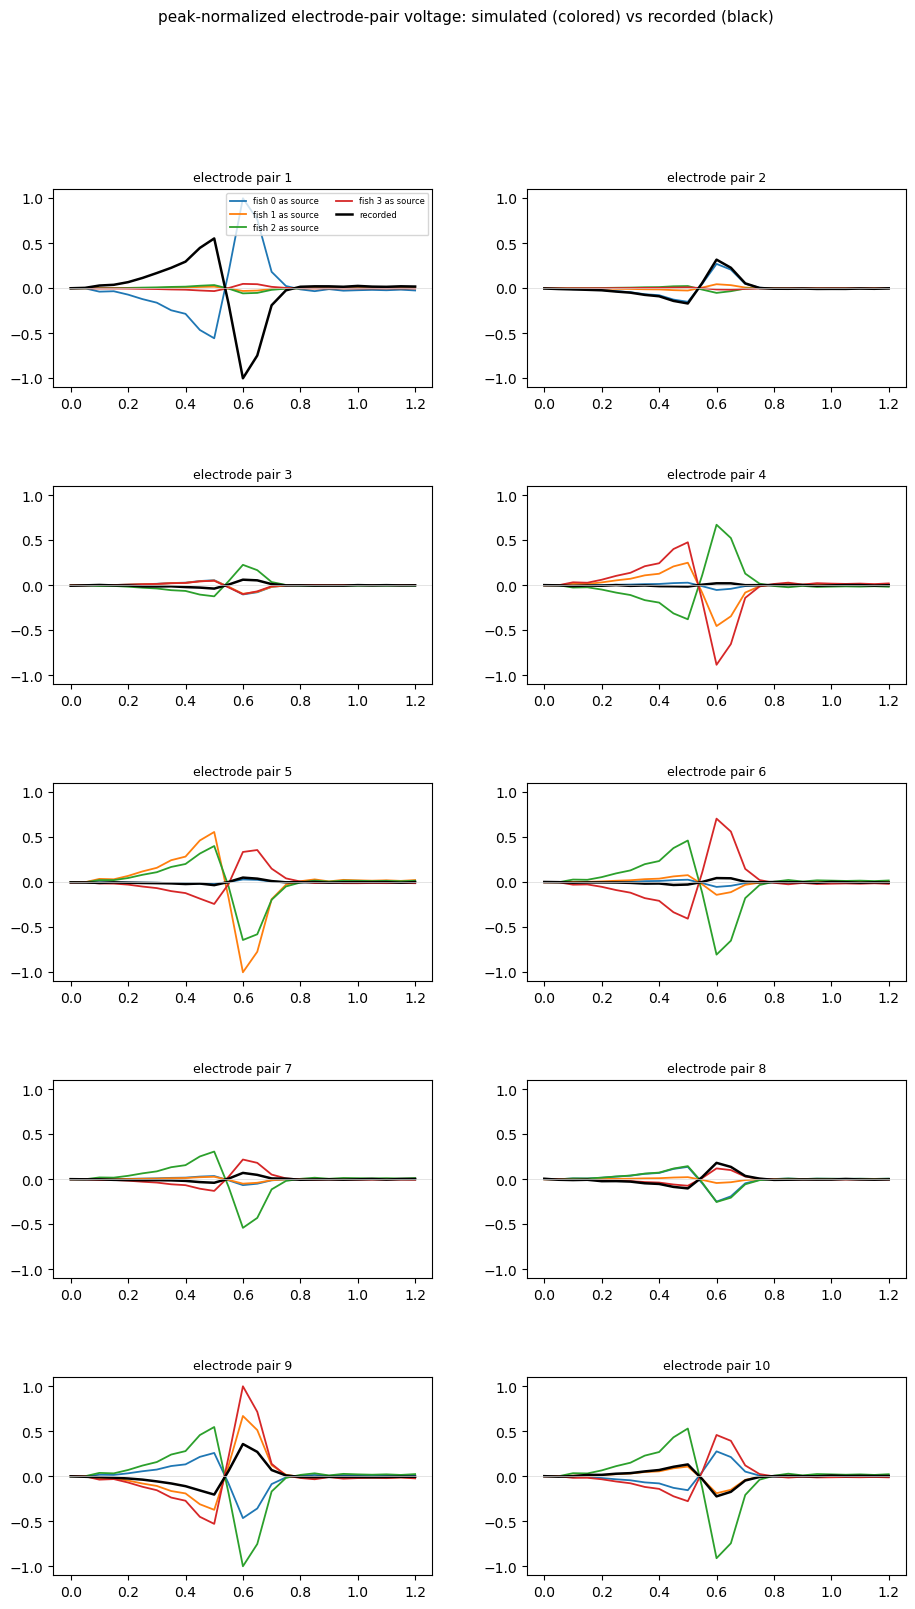

In [13]:
from matplotlib.gridspec import GridSpec

t_ms = np.arange(n_t) * dt * 1e3
colors_fish = plt.cm.tab10.colors
npair = len(pairs); ncol = 2; nrow = int(np.ceil(npair / ncol))
fig = plt.figure(figsize=(11, 3.6 * nrow))
gs = GridSpec(nrow, ncol, figure=fig, hspace=0.5, wspace=0.25)
for k, (pid, _, _) in enumerate(pairs):
    ax = fig.add_subplot(gs[k])
    for sf in range(n_fish):
        ax.plot(t_ms, V_sim[sf][pid], color=colors_fish[sf], lw=1.3, label=f"fish {sf} as source")
    ax.plot(t_ms, V_rec[pid], color='black', lw=1.8, label="recorded")
    ax.axhline(0, color='0.85', lw=0.5); ax.set_ylim(-1.1, 1.1)
    ax.set_title(f"electrode pair {pid}", fontsize=9)
    if k == 0: ax.legend(fontsize=6, ncol=2)
fig.suptitle("peak-normalized electrode-pair voltage: simulated (colored) vs recorded (black)", fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

## 10. EOD-cycle video: real recorded EODs, attributed to whichever fish was closest

Sections 8-9 reconstruct the *full* time-resolved waveform for one source fish at a time
(one LU solve per kept frequency, then an inverse FFT) — accurate, but too slow to repeat for
every frame of a long animation. Here we trade that for a single **quasi-static** solve per
EOD event: at the instant a fish's EOD is at its *peak* current, `dI/dt ≈ 0`, so the capacitive
skin term contributes negligibly and `gamma ≈ sigma` (purely resistive, one real LU solve,
no frequency loop). That's the "instant field" — a snapshot, not the transient shape.

Rather than a synthetic choice of which fish fires, this uses the `df_eod` rows actually
recorded (`Frame` column) within each displayed frame's window — those are real detected EODs,
not invented ones. A displayed frame can have zero, one, or several real EOD rows in its window
(multiple fish *can* genuinely discharge within the same ~20 ms video frame); if there's more
than one, one is picked at random — if there's exactly one, that's the one shown. Whichever row
is picked still needs a fish attached to it: the CSV doesn't label *who* fired, so
`attribute_eod_fish` fits the actual forward model — every candidate fish's unit-current field
is solved, sampled at the electrodes, and compared to the recorded pattern via a least-squares
scalar; whichever fish fits best (lowest residual) is credited, and that fit's scalar becomes
the event's calibrated current amplitude. The real capture is 50 fps; with ~1000 frames
available and `duration_s=30`, playback is stretched to ~1.5x slower than real time.

In [14]:
import matplotlib.animation as animation

def solve_instant_field(fish_mask_frame, N, source_fish, I_peak, delta_h=0.5, n_poles=100,
                        self_only=False, **mat):
    """Quasi-static potential for `source_fish` discharging at peak current I_peak. One
       resistive-only LU solve (omega=0) instead of the per-frequency reconstruction above.
       self_only=False (default): the other fish (this frame's real body masks) are included
       as two-layer boundaries -- the field `source_fish` actually produces in this scene.
       self_only=True: same source, but every material set to sigma_water, so the other fish's
       bodies have no electrical effect -- the "self-image" field source_fish would produce
       alone in open water, isolating its own geometry's contribution from the others'."""
    h = 1.0 / (N - 1)
    midline = fish_midline_from_mask(fish_mask_frame[source_fish])
    pos, cur = multipole_sources(midline, n=n_poles, I0=I_peak)
    b = build_multipole_b(pos, cur, h, N)
    occ = occupancy_field(fish_mask_frame, N, skip=source_fish)
    gw, gs, gi = gammas(0.0, **mat)                 # omega=0 -> resistive-only (eps term vanishes)
    if self_only:
        gs, gi = gw, gw                             # same value everywhere -> occ has no effect
    phi = solve_potential(build_A_shell(occ, N, delta_h, gw, gs, gi), b).real
    return to_grid(phi, N), pos, cur

def sample_phi_point(phi_grid, p, h, N):
    """Bilinear sample of a single (N,N) field at tank-frame point p=(x,y)."""
    fi, fj = p[0] / h, p[1] / h
    i, j = int(fi), int(fj); a, c = fi - i, fj - j
    def w(ii, jj): return phi_grid[min(max(ii, 0), N - 1), min(max(jj, 0), N - 1)]
    return (1-a)*(1-c)*w(i,j) + a*(1-c)*w(i+1,j) + (1-a)*c*w(i,j+1) + a*c*w(i+1,j+1)

def _event_v_rec(row, pairs):
    """Demeaned recorded electrode-pair voltages for one df_eod row, sampled at the single
       instant (shared across all pairs) where the recording's amplitude peaks."""
    pair_ids = [pid for pid, _, _ in pairs]
    V = np.stack([row[[f'electrode_{pid}_time_{i}' for i in range(1, 26)]].to_numpy(dtype=float)
                 for pid in pair_ids])
    V = V - np.nanmean(V, axis=1, keepdims=True)
    t_star = np.unravel_index(np.nanargmax(np.abs(V)), V.shape)[1]
    return V[:, t_star]

def _event_v_sim(fish_mask_frame, f, N, delta_h, n_poles, pairs, **mat):
    """Unit-current (I0=1) WITH-OTHERS field candidate fish f would produce in this frame, and
       its electrode-pair pattern. Returns (v_sim, phi_with_u, pos, cur). Deliberately does NOT
       also solve self_only=True here: that's only ever needed for whichever fish actually wins
       attribution (for the Δφ display), not for every candidate being screened -- solving it
       for all of them (as an earlier version did) wasted ~40% of this step's compute on fields
       that get thrown away."""
    h = 1.0 / (N - 1)
    phi_with_u, pos, cur = solve_instant_field(fish_mask_frame, N, f, 1.0, delta_h, n_poles,
                                               self_only=False, **mat)
    v_sim = np.array([sample_phi_point(phi_with_u, pp, h, N) - sample_phi_point(phi_with_u, pm, h, N)
                      for _, pp, pm in pairs])
    return v_sim, phi_with_u, pos, cur

import gzip, pickle

def _unpack_mask(shape, packed):
    n = int(np.prod(shape))
    buf = np.frombuffer(packed, dtype=np.uint8) if isinstance(packed, (bytes, bytearray)) else packed
    return np.unpackbits(buf, count=n).reshape(shape).astype(bool)

def load_frames_from_mgz(mgz_path, frame_ids):
    """Stream ONLY the requested 0-indexed frames from the full packed .mgz mask file (covers
       the whole ~59997-frame recording, not just the first ~1000 cached to .npy) -- frames
       outside `frame_ids`, and anything past the last one, are never decoded. Returns
       {frame_idx: (n_fish, P, P) bool}, fish ordered consistently (sorted by object id, same
       as the cached .npy). Used both for calibration (events sampled from anywhere in the
       recording) and for rendering windows beyond the cached first ~20s (section 12)."""
    wanted = set(int(f) for f in frame_ids)
    last = max(wanted)
    out = {}
    with gzip.open(mgz_path, "rb") as f:
        pickle.load(f)                                    # header record
        while wanted:
            try:
                frame, objs = pickle.load(f)
            except EOFError:
                break
            if frame > last:                               # records are in order -- nothing left to find
                break
            if frame in wanted:
                order = sorted(objs)
                out[frame] = np.stack([_unpack_mask(*objs[o]) for o in order])
                wanted.discard(frame)
    missing = set(int(f) for f in frame_ids) - out.keys()
    if missing:
        print(f"warning: {len(missing)} requested frames missing from {mgz_path}: {sorted(missing)[:5]}...")
    return out

### Fish attribution: per-event least-squares scalar

`solve_instant_field` works in arbitrary, unit-current model units; the recorded electrodes are
in whatever real units the amplifier/ADC produced. For each candidate fish, the single scalar
that best scales its unit-current pattern onto the recorded pattern is the closed-form
least-squares fit `scalar = (v_sim . v_rec) / (v_sim . v_sim)` -- minimizing
`||scalar*v_sim - v_rec||^2` over that one free parameter. Fit separately per event (not pooled
into one constant across the whole recording): whichever candidate's fitted scalar gives the
lowest residual is the attributed emitter, and that fit's scalar becomes the event's current
amplitude. Only the WINNER then gets a self_only=True solve (for the Δφ display) -- screening
every candidate only ever needs the with-others field.

In [15]:
def attribute_eod_fish(row, pairs, fish_mask_frame, N, delta_h, n_poles, **mat):
    """Forward-model attribution: solve every candidate fish's (non-empty mask this frame)
       unit-current with-others field, sample it at the electrodes, and find the one scalar
       that best scales that fish's predicted pattern onto the recorded pattern (least squares).
       The fish with the lowest residual after that fit is the attributed emitter; its fitted
       scalar becomes the event's calibrated current amplitude. Returns None if no fish has a
       mask this frame, else a dict with keys fish, scalar, phi_with, phi_self, pos, cur."""
    v_rec = _event_v_rec(row, pairs)
    best = None
    for f in range(fish_mask_frame.shape[0]):
        if not fish_mask_frame[f].any():
            continue
        v_sim, phi_with_u, pos, cur = _event_v_sim(fish_mask_frame, f, N, delta_h, n_poles,
                                                   pairs, **mat)
        denom = v_sim @ v_sim
        if denom <= 1e-30:
            continue
        scalar = (v_sim @ v_rec) / denom                  # least-squares (L2) scalar fit
        resid = np.linalg.norm(scalar * v_sim - v_rec)
        if best is None or resid < best["resid"]:
            best = dict(resid=resid, fish=f, scalar=scalar, phi_with_u=phi_with_u, pos=pos, cur=cur)
    if best is None:
        return None
    c = best["scalar"]
    phi_self_u, _, _ = solve_instant_field(fish_mask_frame, N, best["fish"], 1.0, delta_h, n_poles,
                                           self_only=True, **mat)
    return dict(fish=best["fish"], scalar=c, phi_with=c * best["phi_with_u"],
               phi_self=c * phi_self_u, pos=best["pos"], cur=c * best["cur"])

In [16]:
def render_eod_cycle_video(mask_path, df_eod, pairs, N, out_path="eod_cycle.mp4",
                           duration_s=30, frame_stride=10, seed=0, delta_h=0.5, n_poles=100, **mat):
    """Animate real tracked body motion, sampled every `frame_stride` real frames. Each sampled
       frame owns a window of `frame_stride` real frames; any recorded EOD rows (df_eod.Frame,
       1-indexed) falling in that window are real candidates -- one is chosen at random if
       there's more than one, used as-is if there's exactly one, and the frame is left holding
       its previous field if there are none. `attribute_eod_fish` assigns the fish. Output
       always plays back over `duration_s` seconds, regardless of `frame_stride` -- only the
       body-motion resolution changes."""
    rng = np.random.default_rng(seed)
    all_masks = np.load(mask_path, mmap_mode='r')               # (n_fish, n_real_frames, P, P)
    n_real_frames = all_masks.shape[1]
    frame_ids = np.arange(0, n_real_frames, frame_stride)
    fps = max(len(frame_ids) / duration_s, 1.0)
    g = np.linspace(0, 1, N)

    slot_of_row = (df_eod['Frame'] - 1) // frame_stride          # Frame is 1-indexed; masks are 0-indexed
    rows_by_slot = df_eod.groupby(slot_of_row).groups            # slot -> real df_eod row labels in that window

    fig, ax = plt.subplots(figsize=(6, 5.5))
    im = ax.imshow(np.zeros((N, N)), origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r")
    fig.colorbar(im, ax=ax, fraction=0.046, label=r"$\varphi$")
    title = ax.set_title("")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    drawn = []                                                   # per-frame artists to clear
    held = dict(phi=np.zeros((N, N)), pos=None, cur=None, sf=None)
    eod_frames_shown = set()          # a set, not a counter: FuncAnimation.save() can redraw frame 0 twice

    def update(i):
        for art in drawn: art.remove()
        drawn.clear()
        fr = frame_ids[i]
        frame_masks = np.asarray(all_masks[:, fr])               # pulled from disk for this frame only

        row_labels = list(rows_by_slot.get(i, []))                # real EODs in this frame's window
        if row_labels:
            row = df_eod.loc[rng.choice(row_labels)]              # >1 real candidate -> pick one at random
            fit = attribute_eod_fish(row, pairs, frame_masks, N, delta_h, n_poles, **mat)
            if fit is not None:
                held.update(phi=fit["phi_with"], pos=fit["pos"], cur=fit["cur"], sf=fit["fish"])
                eod_frames_shown.add(i)

        vP = np.percentile(np.abs(held["phi"]), 99.5) or 1.0
        im.set_data(held["phi"].T); im.set_clim(-vP, vP)

        for f, m in enumerate(frame_masks):
            if not m.any(): continue
            is_src = f == held["sf"]
            cs = ax.contour(g, g, mask_to_grid(m, N).T.astype(float), levels=[0.5],
                             colors=["#FFD400" if is_src else "lime"],
                             linewidths=1.8 if is_src else 1.0, linestyles="--" if is_src else "-")
            drawn.append(cs)
        if held["pos"] is not None:
            srcp, snkp = held["cur"] > 0, held["cur"] < 0
            drawn.append(ax.scatter(*held["pos"][srcp].T, c="#C0392B", s=14, ec="k", lw=0.3))
            drawn.append(ax.scatter(*held["pos"][snkp].T, marker="s", c="#2C6FBB", s=32, ec="k", lw=0.5))
        sf_txt = f"fish {held['sf']} fires" if held["sf"] is not None else "no EOD yet"
        title.set_text(f"frame {fr}/{n_real_frames - 1} ({len(row_labels)} real EOD(s) this window) — {sf_txt}")
        return [im]

    anim = animation.FuncAnimation(fig, update, frames=len(frame_ids), interval=1000 / fps, blit=False)
    anim.save(out_path, writer=animation.FFMpegWriter(fps=fps, bitrate=2000), dpi=130)
    plt.close(fig)
    print(f"saved {out_path}: {len(frame_ids)} frames @ {fps:.2f} fps -> {len(frame_ids)/fps:.1f}s, "
          f"{len(eod_frames_shown)}/{len(frame_ids)} frames show a real EOD")
    return out_path

Render it. Each shown EOD uses *that event's own* fitted scalar as its current scale, so
field strength varies realistically event to event. `frame_stride=10` windows real frames 10 at
a time; `seed` makes the random tie-break (when a window has several real EODs) reproducible.

In [17]:
mask_path = f'{mgz_file}_masks_first_1000_frames.npy'

render_eod_cycle_video(mask_path, df_eod, pairs, N, out_path="eod_cycle.mp4",
                       duration_s=30, frame_stride=10, seed=0,
                       delta_h=delta_h, n_poles=n_poles, **MAT)

saved eod_cycle.mp4: 101 frames @ 3.37 fps -> 30.0s, 101/101 frames show a real EOD


'eod_cycle.mp4'

## 11. All 4 fish, one video: own field (top) + neighbor perturbation (bottom)

One combined video instead of 4 separate per-fish files stitched together: 4 columns (one per
fish) x 2 rows. Top row is the field that fish actually produces in this scene (other fish
present as two-layer boundaries); bottom row is `dphi = phi_with - phi_self` -- the same
perturbation comparison as section 8's bottom panel, i.e. what the *other* fish's bodies add.

Each displayed frame's window (`frame_stride` real frames) owns at most ONE real EOD event (one
row of `df_eod`, picked at random if the window has several): `attribute_eod_fish` solves every
candidate fish's unit-current field, fits each to the recorded electrode pattern via a
least-squares scalar, and the best-fitting fish is the one column that fires that frame -- the
other 3 stay blank. (This replaced an earlier per-row proximity heuristic that let several fish
fire in the same frame if different raw rows happened to attribute to different fish; the
forward-model fit is keyed to one event at a time, so now it's one fish per frame, at most.)

Both rows use ONE color scale each -- shared across all 4 fish AND across every frame in the
video (two scales total), not an independent scale per panel -- so a color means the same thing
everywhere you look, and panels are directly comparable to each other. That means the whole
video has to be solved *before* any frame can be drawn (the global scale isn't known until every
firing has been computed), so this renders in two passes: solve-and-cache every real firing
first, then animate from that cache. The bottom row gets its own colormap (purple/yellow,
diverging around zero) so it reads as a visually distinct quantity from the top row's field,
and each row gets one shared colorbar on the right.

In [18]:
import matplotlib.colors as mcolors

CMAP_TOP = "RdBu_r"
CMAP_BOTTOM = mcolors.LinearSegmentedColormap.from_list("purple_yellow", ["purple", "white", "gold"])

def render_all_fish_grid_video(mask_source, df_eod, pairs, N, out_path, duration_s=30,
                               frame_stride=10, seed=0, delta_h=0.5, n_poles=100, **mat):
    """One figure, n_fish columns x 2 rows: top = phi_with (that column's fish, with the other
       fish as two-layer boundaries); bottom = dphi = phi_with - phi_self (the perturbation the
       other fish add). A column is blank in both rows on frames where that fish wasn't a real
       attributed emitter in its window. Both rows share ONE color scale each, fixed across the
       whole video (not per-panel, not per-frame) -- computed in an upfront solve-and-cache pass
       before any frame is drawn, since the global scale depends on every firing in the video.
       `mask_source`: path to a dense (n_fish,n_frames,P,P) .npy (mmap'd), or a
       {frame_idx: (n_fish,P,P) bool} dict (e.g. from `load_frames_from_mgz`)."""
    rng = np.random.default_rng(seed)
    if isinstance(mask_source, dict):
        get_frame_masks = mask_source.__getitem__
        n_real_frames = max(mask_source) + 1
        n_fish_v = next(iter(mask_source.values())).shape[0]
    else:
        all_masks = np.load(mask_source, mmap_mode='r')
        get_frame_masks = lambda fr: np.asarray(all_masks[:, fr])
        n_real_frames = all_masks.shape[1]
        n_fish_v = all_masks.shape[0]
    frame_ids = np.arange(0, n_real_frames, frame_stride)
    fps = max(len(frame_ids) / duration_s, 1.0)
    g = np.linspace(0, 1, N)

    slot_of_row = (df_eod['Frame'] - 1) // frame_stride
    rows_by_slot = df_eod.groupby(slot_of_row).groups

    # --- pass 1: solve every real firing once, cache it, and collect the global scale ---
    cache = {}                                          # (i, f) -> dict(phi_with, dphi, pos, cur)
    frame_masks_by_i = {}
    phi_peaks, dphi_peaks = [], []
    for i, fr in enumerate(frame_ids):
        frame_masks = get_frame_masks(fr)
        frame_masks_by_i[i] = frame_masks
        row_labels = list(rows_by_slot.get(i, []))                # real EODs in this frame's window
        if row_labels:
            row = df_eod.loc[rng.choice(row_labels)]              # >1 real candidate -> pick one at random
            fit = attribute_eod_fish(row, pairs, frame_masks, N, delta_h, n_poles, **mat)
            if fit is not None:
                f = fit["fish"]
                dphi = fit["phi_with"] - fit["phi_self"]
                cache[(i, f)] = dict(phi_with=fit["phi_with"], dphi=dphi, pos=fit["pos"], cur=fit["cur"])
                phi_peaks.append(np.abs(fit["phi_with"])); dphi_peaks.append(np.abs(dphi))

    vP = np.percentile(np.concatenate([a.ravel() for a in phi_peaks]), 99.5) if phi_peaks else 1.0
    vD = np.percentile(np.concatenate([a.ravel() for a in dphi_peaks]), 99.0) if dphi_peaks else 1.0
    print(f"global scales from {len(cache)} firings: |phi_with| <~ {vP:.3g}, |dphi| <~ {vD:.3g}")

    # --- pass 2: animate from the cache, using the fixed global scales throughout ---
    fig, axes = plt.subplots(2, n_fish_v, figsize=(5.3 * n_fish_v, 10))   # *dpi stays even (libx264)
    ims = [[None] * n_fish_v, [None] * n_fish_v]
    for f in range(n_fish_v):
        ims[0][f] = axes[0, f].imshow(np.zeros((N, N)), origin="lower", extent=[0, 1, 0, 1],
                                      cmap=CMAP_TOP, vmin=-vP, vmax=vP)
        ims[1][f] = axes[1, f].imshow(np.zeros((N, N)), origin="lower", extent=[0, 1, 0, 1],
                                      cmap=CMAP_BOTTOM, vmin=-vD, vmax=vD)
        for r in range(2):
            axes[r, f].set_xlim(0, 1); axes[r, f].set_ylim(0, 1); axes[r, f].set_aspect("equal")
            axes[r, f].set_xticks([]); axes[r, f].set_yticks([])
        axes[0, f].set_title(f"fish {f} — with other fish", fontsize=9)
        axes[1, f].set_title(f"fish {f} — Δφ (perturbation)", fontsize=9)
    fig.colorbar(ims[0][-1], ax=list(axes[0, :]), fraction=0.015, pad=0.015, label=r"$\varphi$")
    fig.colorbar(ims[1][-1], ax=list(axes[1, :]), fraction=0.015, pad=0.015, label=r"$\Delta\varphi$")
    suptitle = fig.suptitle("")
    drawn = [[[] for _ in range(n_fish_v)] for _ in range(2)]

    def update(i):
        for r in range(2):
            for f in range(n_fish_v):
                for art in drawn[r][f]: art.remove()
                drawn[r][f].clear()
        fr = frame_ids[i]
        frame_masks = frame_masks_by_i[i]
        any_fired = False
        for f in range(n_fish_v):
            hit = cache.get((i, f))
            fired = hit is not None
            if fired:
                ims[0][f].set_data(hit['phi_with'].T)
                ims[1][f].set_data(hit['dphi'].T)
                any_fired = True
            else:
                ims[0][f].set_data(np.zeros((N, N)))
                ims[1][f].set_data(np.zeros((N, N)))

            for r in range(2):
                ax = axes[r, f]
                for ff, m in enumerate(frame_masks):
                    if not m.any(): continue
                    is_target = ff == f
                    cs = ax.contour(g, g, mask_to_grid(m, N).T.astype(float), levels=[0.5],
                                     colors=["#FFD400" if is_target else "lime"],
                                     linewidths=1.8 if is_target else 1.0,
                                     linestyles=("--" if fired else ":") if is_target else "-")
                    drawn[r][f].append(cs)
                if fired:
                    pos, cur = hit['pos'], hit['cur']
                    srcp, snkp = cur > 0, cur < 0
                    drawn[r][f].append(ax.scatter(*pos[srcp].T, c="#C0392B", s=14, ec="k", lw=0.3))
                    drawn[r][f].append(ax.scatter(*pos[snkp].T, marker="s", c="#2C6FBB", s=32, ec="k", lw=0.5))

        suptitle.set_text(f"frame {fr}/{n_real_frames - 1}" + ("" if any_fired else " — no fish fires"))
        return [im for row in ims for im in row]

    anim = animation.FuncAnimation(fig, update, frames=len(frame_ids), interval=1000 / fps, blit=False)
    anim.save(out_path, writer=animation.FFMpegWriter(fps=fps, bitrate=2000), dpi=130)
    plt.close(fig)
    print(f"saved {out_path}: {len(frame_ids)} frames @ {fps:.2f} fps -> {len(frame_ids) / fps:.1f}s, "
          f"{len(cache)} (frame, fish) firings across {n_fish_v} fish")
    return out_path

## 12. Beyond the cached first ~20s: streaming directly from the full packed `.mgz`

Section 11 only used `..._masks_first_1000_frames.npy` — a pre-extracted *cache* of just the
first 1001 frames (~20s), not the full recording. The actual masks for the whole video live
packed (gzip + bit-packed + one pickled record per frame) in `..._masks_packed.mgz`, which
covers all 59997 frames — `load_frames_from_mgz` (defined back in section 10, since calibration
already needed it to sample events from across the whole recording) streams only the specific
frames actually requested from it. Before pulling a bigger range from it, it's worth checking
the two files actually line up: cross-referencing the *independent* `Data_4fish_..csv` tracking
columns (chin/mouth/head/middle/tail pixel positions, nothing to do with the mask file) against
the union of all 4 fish masks at `Frame=1` gives matching pixel bounding boxes (x:[308.6, 759.9]
vs [308, 761], y:[28.3, 854.0] vs [26, 873]) — confirming both that this is the right `.mgz` for
this EOD data, and that `CSV Frame - 1 == mask frame index`. `render_all_fish_grid_video`
already accepts either a `.npy` path or a `{frame_idx: masks}` dict, so the rest of the pipeline
is unchanged.

First, a quick 10-second check (50 fps -> 500 real frames, `frame_stride=10` -> 50
displayed frames, `duration_s = 1.5 * 500/50 = 15s`) before committing to the full 2-minute
render.

In [19]:
real_fps = 50.0

window_s_test = 10
stride_test = 10
n_real_frames_test = int(window_s_test * real_fps)                 # 500
frame_ids_test = np.arange(0, n_real_frames_test, stride_test)      # 50 frames needed
duration_s_test = 1.5 * n_real_frames_test / real_fps               # 15.0s

frames_test = load_frames_from_mgz(mgz_file, frame_ids_test)
print(f"loaded {len(frames_test)}/{len(frame_ids_test)} frames covering "
      f"the first {window_s_test}s ({n_real_frames_test} real frames)")

render_all_fish_grid_video(frames_test, df_eod, pairs, N,
                           f"eod_grid_{window_s_test}s_test_stride{stride_test}.mp4",
                           duration_s=duration_s_test, frame_stride=stride_test, seed=0,
                           delta_h=delta_h, n_poles=n_poles, **MAT)

loaded 50/50 frames covering the first 10s (500 real frames)


global scales from 50 firings: |phi_with| <~ 0.0933, |dphi| <~ 0.0118


saved eod_grid_10s_test_stride10.mp4: 50 frames @ 3.33 fps -> 15.0s, 50 (frame, fish) firings across 4 fish


'eod_grid_10s_test_stride10.mp4'

Once the 10s check looks right, render the full first 2 minutes (6000 real frames) the
same way, at `frame_stride=10` (`duration_s = 1.5 * 6000/50 = 180s`).

In [20]:
window_min = 2
stride_2min = 10
n_real_frames_2min = int(window_min * 60 * real_fps)               # 6000
frame_ids_2min = np.arange(0, n_real_frames_2min, stride_2min)      # 600 frames needed
duration_s_2min = 1.5 * n_real_frames_2min / real_fps               # 180.0s

frames_2min = load_frames_from_mgz(mgz_file, frame_ids_2min)
print(f"loaded {len(frames_2min)}/{len(frame_ids_2min)} frames covering "
      f"the first {window_min} min ({n_real_frames_2min} real frames)")

render_all_fish_grid_video(frames_2min, df_eod, pairs, N, f"eod_grid_2min_stride{stride_2min}.mp4",
                           duration_s=duration_s_2min, frame_stride=stride_2min, seed=0,
                           delta_h=delta_h, n_poles=n_poles, **MAT)

loaded 600/600 frames covering the first 2 min (6000 real frames)


global scales from 600 firings: |phi_with| <~ 0.0823, |dphi| <~ 0.00871


saved eod_grid_2min_stride10.mp4: 600 frames @ 3.33 fps -> 180.0s, 600 (frame, fish) firings across 4 fish


'eod_grid_2min_stride10.mp4'

## Notes

- The interactive `ipywidgets` frame slider and the per-fish `.mp4` field animation from the
  original notebook are omitted here for brevity — both just drive `solve_source_fish` over
  `range(n_t)`, so they can be added back on top of this pipeline unchanged.
- Dropped as dead/superseded code from the original: the uniform-grid Laplacian builders
  (`build_A_gamma`, `build_A_gamma_theta`) and `material_layers`, both replaced by the
  sub-cell `occupancy_field` / `build_A_shell` shell model; the straight-line (PCA-only)
  multipole placement, replaced by the curved-midline version; and the electrode-axis
  transform exploration cell (four transforms were tried — `load_electrode_pairs` already
  hardcodes the one that was chosen).
- `render_eod_cycle_video` / `render_all_fish_grid_video` (sections 10-11) use a quasi-static
  (peak-current, resistive-only) approximation per EOD event rather than the full
  per-frequency reconstruction — appropriate for a long animation, but it won't show the
  capacitive waveform-shape distortion that sections 8-9 do. Fish attribution
  (`attribute_eod_fish`) fits every candidate fish's unit-current field to the recorded
  electrode pattern via a per-event least-squares scalar, and picks whichever fits best —
  stronger than a geometric heuristic, but still a best fit against the current two-layer
  model, not a verified ground-truth label. (A variant that pools many events into one shared
  calibration scalar via alternating minimization was tried and reverted — the per-event fit
  below is what's actually in use.)
- `multipole_sources`'s total current is exactly `I0`, with no implicit body-length scaling —
  removed because `I0` is typically a real recorded (or least-squares fitted) amplitude, which
  already reflects whatever that individual fish actually produced; an extra `* length`
  multiplier would have double-counted any genuine size-dependence already present in the data.
  A longer fish's body still affects the field shape purely geometrically, since its multipole
  sources are spread over more of its own (longer) midline.
- Section 12 only decodes the specific frames it needs from the full `.mgz`, so it's cheap in
  time/memory for a sparse sample (e.g. `frame_stride=10` over a few minutes) — decoding a
  *dense* range (every single frame, or many minutes at a fine stride) would need a different,
  truly-streaming approach that never holds more than a few frames in memory at once, since
  `load_frames_from_mgz` currently keeps every requested frame's masks resident until it
  returns.